# 4 · The connecting rod — hand calculation

**Engine design basics — notebook 4.**

The con-rod is the cleanest example of how engine parts are sized: two load
cases from notebook 3, a handful of beam formulas, a buckling check and a
fatigue check. A real rod is finished in FE (the eye and cap are curved beams with
contact and bolt preload), but the hand calculation tells you whether the
section is in the right ballpark and **which load case drives which feature**.

**You should come out knowing:**
- the two classic load cases (tension at gas-exchange TDC, compression at firing) and where they occur in the speed range,
- why rod buckling is checked in two planes with different effective lengths, and why a short race rod is a *strength* problem more than a buckling problem,
- how a per-speed fatigue check differs from "max tension vs max compression",
- first-order estimates for whipping, small end, big-end cap and rod bolts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import enginecalc as ec
from enginecalc import SERIES, INK, INK2, GRID, tidy
ec.use_style()

eng = ec.Engine()
th, p_nom, ex = ec.pressure_trace(eng)
deg = np.degrees(th)
mat = ec.MATERIALS["Ti-6Al-4V"]
print(mat)

Material(name='Ti-6Al-4V (annealed/STA)', E=114000000000.0, Rp02=880000000.0, Rm=950000000.0, sigma_w=510000000.0, rho=4430)


## 4.1 · Design inputs

| input | value | comment |
|---|---|---|
| rev limit | 16 000 rpm | |
| overspeed case | 16 500 rpm | missed shift / limiter overshoot |
| design $p_{max}$ | nominal × 1.15 | calibration scatter, cyclic variation, knock margin |
| shank section | I-beam, see below | web in the plane of rotation |
| mass above the critical shank section | piston group + small end ≈ 30 g | only this mass loads the section in tension |

The shank section is taken just below the small end (where the section is
smallest and the most mass is still "hanging" on it in tension).

In [2]:
n_max, n_over = 16000, 16500
p_design_factor = 1.15
m_above = eng.m_piston_group + 0.030            # [kg] mass outboard of the section

# I-section, dimensions in m: H in the plane of rotation, B along the crank axis
H, B, tf, tw = 22e-3, 16e-3, 3.0e-3, 3.5e-3
A, I_in, I_out = ec.i_section(B, H, tf, tw)
print(f"A = {A*1e6:.0f} mm²,  I_in-plane = {I_in*1e12:.0f} mm⁴,  I_out-of-plane = {I_out*1e12:.0f} mm⁴,  "
      f"ratio {I_in/I_out:.1f}")

A = 152 mm²,  I_in-plane = 9931 mm⁴,  I_out-of-plane = 2105 mm⁴,  ratio 4.7


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


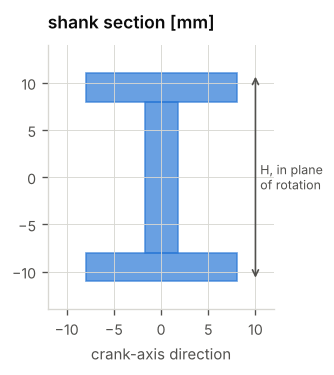

In [3]:
fig, ax = plt.subplots(figsize=(3, 3.2))
from matplotlib.patches import Rectangle
hw = H - 2*tf
for (x0, y0, w_, h_) in [(-B/2, H/2-tf, B, tf), (-B/2, -H/2, B, tf), (-tw/2, -hw/2, tw, hw)]:
    ax.add_patch(Rectangle((x0*1e3, y0*1e3), w_*1e3, h_*1e3, color=SERIES[0], alpha=0.7))
ax.set_aspect("equal"); ax.set_xlim(-12, 12); ax.set_ylim(-14, 14)
ax.annotate("", (10, H/2*1e3), (10, -H/2*1e3), arrowprops=dict(arrowstyle="<->", color=INK2))
ax.text(10.5, 0, "H, in plane\nof rotation", fontsize=7.5, va="center", color=INK2)
tidy(ax, title="shank section [mm]")
ax.set_xlabel("crank-axis direction")
plt.tight_layout(); plt.show()

## 4.2 · Load cases

**Tension** — at gas-exchange TDC, only inertia, only the mass outboard of the section:

$$F_{t} = m_{above}\,r\omega^2(1+\lambda) - (p_{GX}-p_{cc})A_K$$

**Compression** — around firing TDC, design pressure, inertia relief at that speed:

$$F_{c} = \max_\theta\left[(p\cdot k_{p}-p_{cc})A_K - m_{above}\,\ddot x\right] / \cos\beta$$

The largest $F_c$ is at **low** speed (little inertia relief), the largest
$F_t$ at **overspeed**. They never occur in the same cycle — keep that in mind for
fatigue.

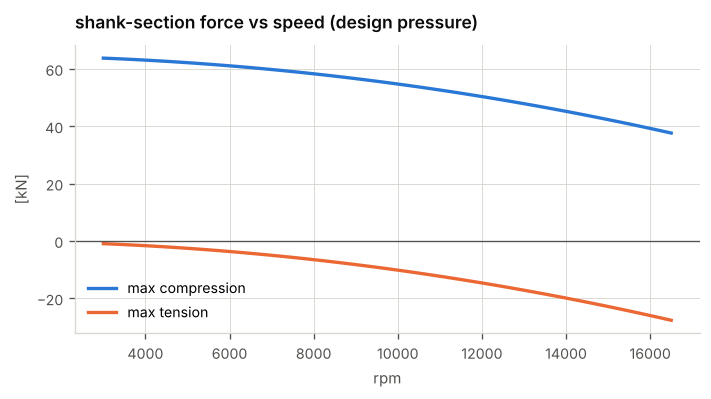

max compression  F_c = 63.7 kN  at 3000 rpm
max tension      F_t = 27.7 kN  at 16500 rpm
hand formula F_t = 27.6 kN (gas ignored)


In [4]:
def section_force(n, k_p=1.0):
    """Axial rod force at the shank section over the cycle (+ = compression)."""
    w = ec.rpm_to_omega(n)
    p = np.where(np.abs(th) < np.pi, eng.p_crankcase + (p_nom - eng.p_crankcase) * k_p, p_nom)
    _, _, a = ec.piston_kinematics(eng, th, w)
    beta = ec.rod_angle(eng, th)
    return ((p - eng.p_crankcase) * eng.A_piston - m_above * a) / np.cos(beta)

rpms = np.arange(3000, n_over + 1, 250)
Fc = np.array([section_force(n, p_design_factor).max() for n in rpms])
Ft = np.array([section_force(n, p_design_factor).min() for n in rpms])

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(rpms, Fc / 1e3, label="max compression")
ax.plot(rpms, Ft / 1e3, label="max tension")
ax.axhline(0, color=INK2, lw=0.8)
tidy(ax, title="shank-section force vs speed (design pressure)", xlabel="rpm", ylabel="[kN]")
ax.legend(); plt.tight_layout(); plt.show()

F_comp = Fc.max(); F_tens = -Ft.min()
print(f"max compression  F_c = {F_comp/1e3:.1f} kN  at {rpms[Fc.argmax()]} rpm")
print(f"max tension      F_t = {F_tens/1e3:.1f} kN  at {rpms[Ft.argmin()]} rpm")
print(f"hand formula F_t = {m_above*eng.r*ec.rpm_to_omega(n_over)**2*(1+eng.lam)/1e3:.1f} kN (gas ignored)")

## 4.3 · Static stresses in the shank

$$\sigma_c = \frac{F_c}{A}\qquad \sigma_t = \frac{F_t}{A}\qquad S = \frac{R_{p0.2}}{\sigma}$$

In [5]:
sig_c, sig_t = F_comp / A, F_tens / A
print(f"compression  σ_c = {sig_c/1e6:.0f} MPa   ->  S vs Rp0.2 = {mat.Rp02/sig_c:.2f}")
print(f"tension      σ_t = {sig_t/1e6:.0f} MPa   ->  S vs Rp0.2 = {mat.Rp02/sig_t:.2f}")

compression  σ_c = 419 MPa   ->  S vs Rp0.2 = 2.10
tension      σ_t = 182 MPa   ->  S vs Rp0.2 = 4.84


## 4.4 · Buckling — two planes, two effective lengths

- **In the plane of rotation** the rod is pinned at both ends (pin and crank pin
  rotate freely): $L_{eff} = l$.
- **Out of plane** (along the crank axis) the eyes are clamped by piston bosses and
  crank cheeks: closer to fixed–fixed, $L_{eff}\approx 0.5\,l$.

Equal safety in both planes therefore needs $I_{in} \approx 4\,I_{out}$ — the reason
rods are deeper (H) than wide (B).

For short columns the Euler load exceeds the yield load; the **Johnson parabola**
bridges the gap:

$$\sigma_{cr} = \sigma_y - \frac{1}{E}\left(\frac{\sigma_y}{2\pi}\frac{L_{eff}}{k}\right)^2,
\quad k=\sqrt{I/A},\quad\text{valid for } \frac{L_{eff}}{k} < \sqrt{\frac{2\pi^2E}{\sigma_y}}$$

in-plane (L = l)           L/k =  13.0   P_cr =  129.3 kN   S = 2.03
out-of-plane (L = 0.5 l)   L/k =  14.1   P_cr =  128.6 kN   S = 2.02


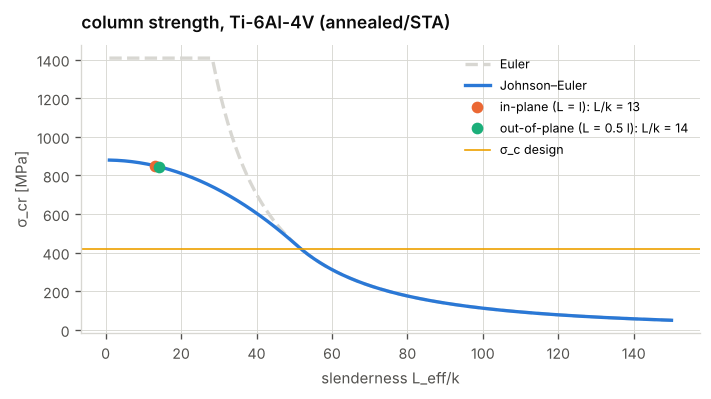

Euler/Johnson transition at L/k = 51


In [6]:
l = eng.rod_length
cases = {"in-plane (L = l)": (I_in, l), "out-of-plane (L = 0.5 l)": (I_out, 0.5 * l)}
SR = np.linspace(1, 150, 300)
trans = np.sqrt(2*np.pi**2*mat.E/mat.Rp02)
sig_eul = np.pi**2*mat.E/SR**2
sig_joh = mat.Rp02 - (mat.Rp02*SR/(2*np.pi))**2/mat.E
sig_cr = np.where(SR < trans, sig_joh, sig_eul)

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(SR, np.minimum(sig_eul, 1.6*mat.Rp02)/1e6, ls="--", color=GRID, label="Euler")
ax.plot(SR, sig_cr/1e6, label="Johnson–Euler")
for i, (name, (I, Le)) in enumerate(cases.items()):
    k = np.sqrt(I / A); s = Le / k
    Pcr = ec.johnson_buckling(mat.E, I, A, Le, mat.Rp02)
    ax.plot(s, Pcr/A/1e6, "o", color=SERIES[i+1], label=f"{name}: L/k = {s:.0f}")
    print(f"{name:<26} L/k = {s:5.1f}   P_cr = {Pcr/1e3:6.1f} kN   S = {Pcr/F_comp:.2f}")
ax.axhline(sig_c/1e6, color=SERIES[3], lw=1, label="σ_c design")
tidy(ax, title=f"column strength, {mat.name}", xlabel="slenderness L_eff/k", ylabel="σ_cr [MPa]")
ax.legend(fontsize=7.5); plt.tight_layout(); plt.show()
print(f"Euler/Johnson transition at L/k = {trans:.0f}")

A short race rod sits far left on this curve: the critical stress is barely below
yield. The buckling check then mainly protects against an unfavourable $H/B$
ratio — not against classic slender-column failure.

## 4.5 · Whipping (lateral inertia bending)

The shank swings with the rod: its points accelerate sideways with an
amplitude that grows linearly from 0 at the small end to $r\omega^2$ at the big end.
Treated as a simply supported beam with this triangular load, the classical
maximum moment (around $\theta\approx 90°$) is

$$M_{whip} \approx \frac{m_{shank}\,r\,\omega^2\,l}{9\sqrt3}$$

In [7]:
w = ec.rpm_to_omega(n_over)
m_shank = mat.rho * A * l
M_whip = m_shank * eng.r * w**2 * l / (9*np.sqrt(3))
sig_whip = M_whip / (I_in / (H/2))
print(f"shank mass ≈ {m_shank*1e3:.0f} g,  M_whip = {M_whip:.1f} N·m,  σ_bend = {sig_whip/1e6:.0f} MPa  @ {n_over} rpm")

shank mass ≈ 71 g,  M_whip = 34.5 N·m,  σ_bend = 38 MPa  @ 16500 rpm


Small compared with $\sigma_c$, and it peaks at 90° where the axial load is
moderate — but on a very high-speed rod it is not negligible, and it is a bending
stress, i.e. maximum at the flange surface where fatigue cracks start.

## 4.6 · Fatigue — per operating point

A rod at one speed sees, every cycle, a swing from its tension at gas-exchange
TDC to its compression at firing. The fatigue check is therefore **per speed**:

$$\sigma_a = \frac{\sigma_{max}-\sigma_{min}}{2},\qquad \sigma_m = \frac{\sigma_{max}+\sigma_{min}}{2}$$

with the modified Goodman line $\frac{1}{S} = \frac{\sigma_a}{\sigma_W'} + \frac{\sigma_m}{R_m}$
(a compressive mean stress is conservatively given no benefit). $\sigma_W'$ is the
specimen fatigue strength reduced for surface, size and notch effects — here a
blanket factor 0.75, purely illustrative.

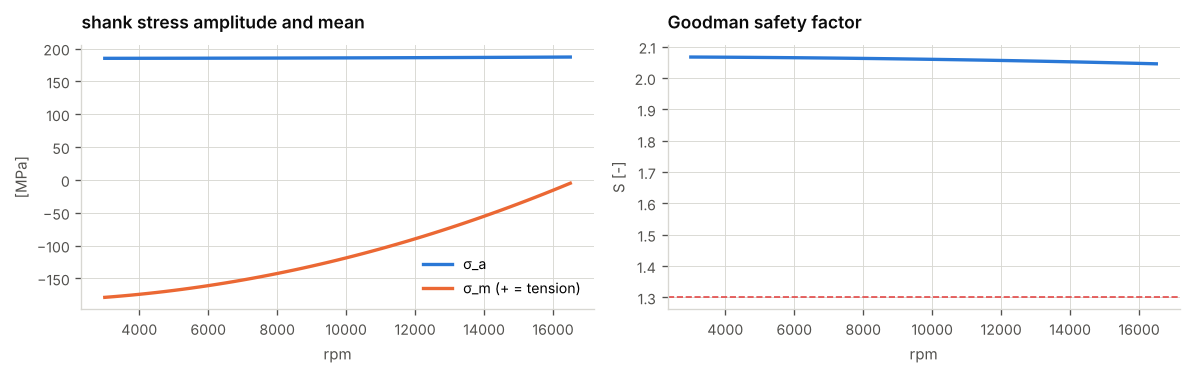

lowest fatigue safety S = 2.05 at 16500 rpm  (target ≳ 1.3, illustrative)
naive check (max tension and max compression as if in the same cycle): σ_a = 273 MPa, S = 1.40  <- pessimistic


In [8]:
k_fat = 0.75
sigW = mat.sigma_w * k_fat
S_fat, sa_l, sm_l = [], [], []
for n in rpms:
    F = section_force(n, 1.0)                       # nominal pressure for fatigue
    smax_t = -F.min() / A                           # tension positive for stress
    smax_c = F.max() / A
    sa = (smax_t + smax_c) / 2
    sm = (smax_t - smax_c) / 2
    sa_l.append(sa); sm_l.append(sm)
    S_fat.append(ec.goodman_safety(sa, sm, sigW, mat.Rm))
S_fat = np.array(S_fat)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(rpms, np.array(sa_l)/1e6, label="σ_a"); axs[0].plot(rpms, np.array(sm_l)/1e6, label="σ_m (+ = tension)")
tidy(axs[0], title="shank stress amplitude and mean", xlabel="rpm", ylabel="[MPa]"); axs[0].legend()
axs[1].plot(rpms, S_fat); axs[1].axhline(1.3, color=SERIES[7], lw=1, ls="--")
tidy(axs[1], title="Goodman safety factor", xlabel="rpm", ylabel="S [-]")
plt.tight_layout(); plt.show()
i = S_fat.argmin()
print(f"lowest fatigue safety S = {S_fat[i]:.2f} at {rpms[i]} rpm  (target ≳ 1.3, illustrative)")
Fc_nom = max(section_force(n, 1.0).max() for n in rpms)
sa_naive = (F_tens / A + Fc_nom / A) / 2
print(f"naive check (max tension and max compression as if in the same cycle): "
      f"σ_a = {sa_naive/1e6:.0f} MPa, S = {sigW/sa_naive:.2f}  <- pessimistic")

Interesting: the **amplitude is almost speed-independent**. As speed rises the
inertia relief reduces compression while tension grows by about the same amount,
so the swing between them stays similar and only the *mean* shifts from
compression towards tension. (Here the gas force is the same at every speed —
constant full-load trace — which makes this especially clean.)

With Goodman penalising tensile mean stress, high speed is the slightly worse
point here. With a heavier piston or a higher rev limit the mean goes clearly into
tension and high speed becomes *the* critical fatigue point — while the naive
"max tension vs max compression" check would point you to the wrong speed and
give a wrong number.

## 4.7 · Small end, big-end cap, bolts — first estimates

These areas are curved, have contact and preload: FE is the real tool. Hand
estimates still give the right order of magnitude and the load that matters.

In [9]:
# --- small end -------------------------------------------------------------
d_pin, b_se, t_eye = 18e-3, 20e-3, 4.0e-3       # pin dia, small-end width, eye wall thickness
p_se = F_comp / (d_pin * b_se)
F_se_t = eng.m_piston_group * eng.r * w**2 * (1 + eng.lam)
sig_eye = F_se_t / (2 * b_se * t_eye)
print("SMALL END")
print(f"  projected bearing pressure (compression)  p = F_c/(d·b) = {p_se/1e6:.0f} MPa")
print(f"  eye tension, piston group pulling        F = {F_se_t/1e3:.1f} kN -> σ ≈ F/(2bt) = {sig_eye/1e6:.0f} MPa "
      f"(+ curved-beam bending: real peak typically 2–3×)")

# --- big end cap -----------------------------------------------------------
c_bolt, b_cap, h_cap = 46e-3, 20e-3, 13e-3      # bolt spacing, cap width, equiv. cap height at centre
F_cap = eng.m_osc * eng.r * w**2 * (1 + eng.lam) + (eng.m_rod_rot - eng.m_rod_cap) * eng.r * w**2
W_cap = b_cap * h_cap**2 / 6
print("\nBIG-END CAP @ overspeed")
print(f"  cap load F_cap = {F_cap/1e3:.1f} kN  (reciprocating mass + rotating rod mass above the split line)")
for name, div in (("simply supported, F·c/8", 8), ("fixed–fixed ends, F·c/12", 12)):
    M = F_cap * c_bolt / div
    print(f"  {name:<26} M = {M:5.0f} N·m   σ = {M/W_cap/1e6:4.0f} MPa")

# --- rod bolts ---------------------------------------------------------------
d, P = 9e-3, 1e-3                               # M9x1
d2, d3 = d - 0.6495*P, d - 1.2269*P
As = np.pi/4 * ((d2 + d3)/2)**2
F_A = F_cap / 2
F_V = 2.0 * F_A                                  # rule of thumb: preload ≈ 2× working load per bolt
print("\nROD BOLTS (2 × M9x1)")
print(f"  stress area A_s = {As*1e6:.1f} mm²,  working load per bolt F_A = {F_A/1e3:.1f} kN")
print(f"  preload ≈ 2·F_A = {F_V/1e3:.1f} kN  ->  σ_V = {F_V/As/1e6:.0f} MPa  "
      f"(needs a ≥1400 MPa class bolt material; preload by stretch, not torque)")

SMALL END
  projected bearing pressure (compression)  p = F_c/(d·b) = 177 MPa
  eye tension, piston group pulling        F = 25.0 kN -> σ ≈ F/(2bt) = 156 MPa (+ curved-beam bending: real peak typically 2–3×)

BIG-END CAP @ overspeed
  cap load F_cap = 43.3 kN  (reciprocating mass + rotating rod mass above the split line)
  simply supported, F·c/8    M =   249 N·m   σ =  442 MPa
  fixed–fixed ends, F·c/12   M =   166 N·m   σ =  294 MPa

ROD BOLTS (2 × M9x1)
  stress area A_s = 51.0 mm²,  working load per bolt F_A = 21.6 kN
  preload ≈ 2·F_A = 43.3 kN  ->  σ_V = 848 MPa  (needs a ≥1400 MPa class bolt material; preload by stretch, not torque)


Why preload ≈ 2× the working load? The joint must stay closed: if the cap
separates from the rod at the split line, the bore goes out of round, the shells
fret and the bolt suddenly sees the full alternating load. Because the bolt is
much softer than the clamped parts, only a fraction ($\Phi\approx$ 0.1–0.3) of the
working load reaches the bolt as long as the joint is closed — that is the whole
idea of a preloaded joint (VDI 2230 is the full method).

## 4.8 · The mass spiral

Every gram on the piston group adds tension to rod, cap and bolts:

In [10]:
dF_dm = eng.r * w**2 * (1 + eng.lam)
print(f"@ {n_over} rpm: +10 g reciprocating mass -> +{dF_dm*0.010/1e3:.2f} kN tension "
      f"(+{dF_dm*0.010/F_tens*100:.1f} % of F_t)")
print(f"  ... and a heavier rod/cap to carry it adds more mass in turn: lightweight design compounds.")

@ 16500 rpm: +10 g reciprocating mass -> +0.89 kN tension (+3.2 % of F_t)
  ... and a heavier rod/cap to carry it adds more mass in turn: lightweight design compounds.


## 4.9 · Take-aways

- **Compression** load case: design $p_{max}$, low speed. **Tension**: overspeed, gas-exchange TDC, mass *outboard of the section* only.
- Buckling in two planes ($L_{eff} = l$ in-plane, ≈ 0.5 $l$ out-of-plane) → $I_{in}\approx4I_{out}$. Short rods are Johnson/yield-governed.
- Fatigue must be checked per speed; the swing is nearly constant, the mean moves to tension at high speed → high speed is critical.
- Cap and bolts are driven by the inertia of *everything* above the split line; preload must keep the joint closed.
- Whipping is a bending stress at the flange surface — small but not zero.

**Exercises**

1. Find the lightest $H$ (keeping $B$, $t_f$, $t_w$) that still gives $S \ge 1.3$ in fatigue and $S\ge1.5$ in compression.
2. Repeat with steel (`ec.MATERIALS["34CrNiMo6"]`). Same safety factors: how much heavier is the shank?
3. Shift the critical section to mid-shank (more mass above it, longer distance). Does the result change much?
4. Compute the Euler load in-plane for a slender rod ($l = 160$ mm, same section). When does buckling become the governing criterion?

**Next (roadmap):** piston & pin, then the crankshaft, then plain bearings.